In [2]:
## Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "DesyneMartinez"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}
## Set working drive to today's lecture:

setwd("STAT-7110-Quality-Control//Assignments//HW3")

## Homework 3 - Analysis Using the $p$, $np$, $c$, and $u$ Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 16, 2026 via D2L**

## Instructions:

Ravi's Comics and Games is a local comic book and tabletop game shop that receives weekly new-release shipments from a regional distributor. Ravi's customers, especially the collectors chasing near-mint copies, have started complaining more often about comics arriving with scratched or folded covers, and Ravi has noticed it's starting to hurt sales of his higher-end back issues too. He's asked your quality control team to help him figure out how bad the problem really is, whether it's getting better or worse, and who -- the distributor, or his own shop -- is responsible.

Your team decides to look at this two different ways. First, every comic in a week's shipment gets a quick pass/fail condition check as staff unbox and shelve it (any visible scratch, crease, or fold on the cover marks it nonconforming). Because the number of comics in a shipment varies week to week depending on the new-release schedule, your team tracks both the **rate** of nonconforming comics (useful for spotting trends) and the **raw count** (useful when Ravi calls the distributor's account representative, who thinks in terms of "how many books," not percentages).

Second, your team recognizes that a single comic can have more than one distinct defect on it -- a scratch on the front cover **and** a folded corner on the back, for example -- so a simple pass/fail check doesn't capture the full severity of the damage. To get a fuller picture, staff also perform a more detailed defect count each week, counting every individual scratch, fold, or dent they find (not just how many comics have at least one). This detailed count is done on two separate parts of the shop: a **fixed** sample of 5 boxes pulled from the new-release shipment every week, and a **variable** number of already-shelved back-issue boxes, inspected whenever staff have the time.

## Key Specifications

| Quantity | Value |
|---|---|
| Nonconforming definition (Datasets A) | Any visible scratch, crease, or fold on the cover |
| Nonconformity definition (Datasets B & C) | Each individual scratch, fold, or dent found (a comic may have more than one) |
| Dataset A: Shipment Condition, Phase I weeks (m) | 25 weeks, variable shipment size |
| Dataset A: Shipment Condition, Phase II weeks (m) | 20 weeks, variable shipment size |
| Dataset B: New-Release Defect Counts, weeks (m) | 25 weeks, fixed sample of 5 boxes/week |
| Dataset C: Back-Issue Defect Counts, weeks (m) | 25 weeks, variable number of boxes/week |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis
The purpose of this analysis is to identify the root cause of why Ravi is receiving comics that are not in pristine mint condition. The consumers are complaining of scratches, folds, and creases in the comics which devalue the comics themselves. We need to investigate how bad the problem really is by seeking out these comics that are coming in each week in poor conditions and whether its the distributor, or his own shop is responsible.
### Q2: Ravi's team is monitoring two distinct quality characteristics here: a pass/fail condition check, and a detailed defect count. For each, classify the type of attribute data being collected, and briefly explain how this differs from the continuous, normally-distributed data used in your previous two homeworks.
For the first quality characteristic with the pass/fail conditon check we are looking at the Number Nonconforming attribute  and in the second quality characteristic we are looking at the number of defects attribute which are both numeric continous variables. These are different from the previous continuous variables in the other analyses because in the first quality characteristic the purpose is to identify whether a comic is in mint condition or not making it binary dichotimized outcome. The second characteristic differs because we are seeking out the number of defects per unit.



### Q3: For the pass/fail data (Dataset A), what practical factor determines whether you should build a $p$ chart or an $np$ chart? For the detailed defect-count data (Datasets B and C), what practical factor determines whether you should build a $c$ chart or a $u$ chart?
For the pass/fail data the reason we should implement a P or NP chart is because we are looking at numeric metrics with a binary outcome. For the detailed defect count data we would implement a C or U chart since we are wanting the number of defects(nonconformities) per unit.

## Analyze

### Q4: Read the Phase I Shipment Condition data (Dataset A) into R. Construct a Phase I $p$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Package 'qcc' version 2.7

Type 'citation("qcc")' for citing this R package in publications.



Rows: 25
Columns: 3
$ Week                <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ TotalComics         <dbl> 194, 216, 149, 142, 124, 212, 144, 117, 187, 201, …
$ NumberNonconforming <dbl> 7, 8, 6, 8, 5, 17, 11, 2, 9, 8, 9, 11, 9, 74, 7, 6…


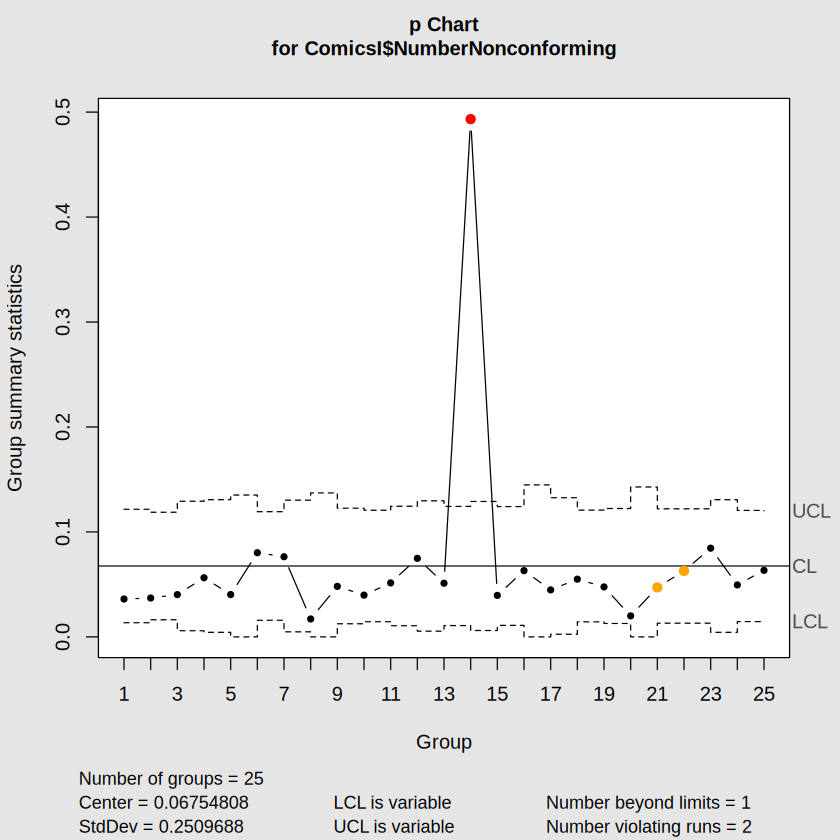

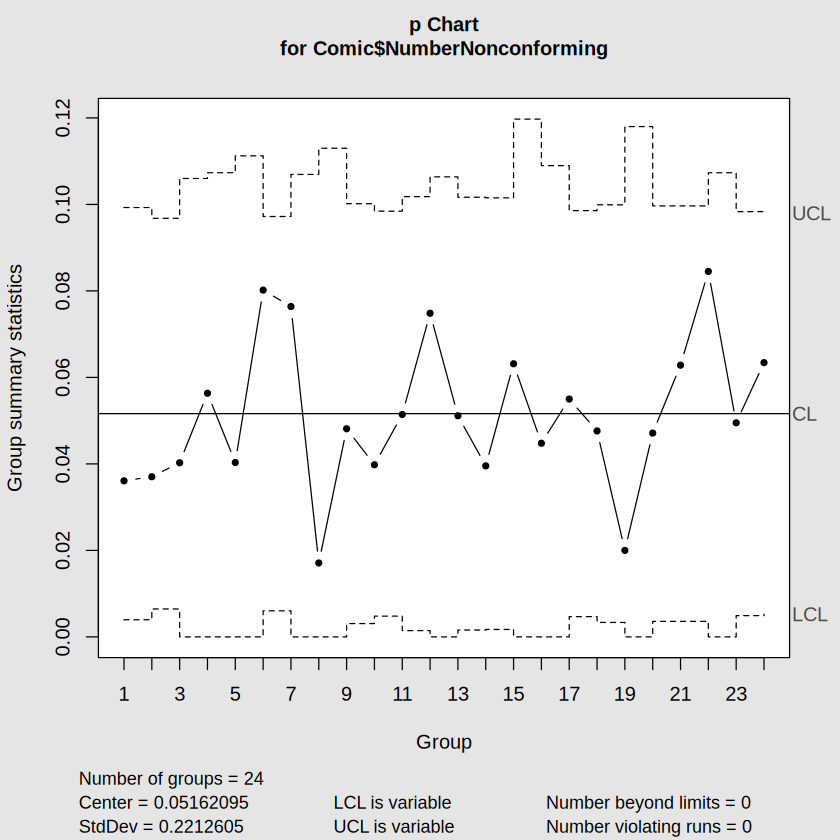

In [3]:
## Q4 Code ##

## Load the libraries ##
install.packages("qcc")
library(tidyverse)
library(readxl)
library(qcc)

## Read in the Data ##

ComicsI <- read_excel("RavisComics_ShipmentCondition_PhaseI.xlsx")

## Data Integrity Check ##

ComicsI |>
  glimpse()

#Our plotting statistic is the sample proportion nonconforming
#So our p in this case would be the number of nonconforming comics (With folds creases etc..)
#Attribute used: NumberNonconforming.
#The UCL and LCL would be variable since the sample size differs each week.

  Comic_chart <- qcc(ComicsI$`NumberNonconforming`,
                    type="p",
                    sizes=ComicsI$`TotalComics`,
                    plot=TRUE)


ooc_points <- Comic_chart$violations$beyond.limits

Comic <- ComicsI[-ooc_points,]

Comic_chart1 <- qcc(Comic$`NumberNonconforming`,
                    type="p",
                    sizes=Comic$`TotalComics`,
                    plot=TRUE)


### Q5: Repeat the analysis in Q4, this time constructing an $np$ chart on the same data. Do your conclusions about which week(s) are out of control change? Which chart do you think would be easier to explain to the distributor's account representative, and why?

Rows: 25
Columns: 3
$ Week                <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ TotalComics         <dbl> 194, 216, 149, 142, 124, 212, 144, 117, 187, 201, …
$ NumberNonconforming <dbl> 7, 8, 6, 8, 5, 17, 11, 2, 9, 8, 9, 11, 9, 74, 7, 6…


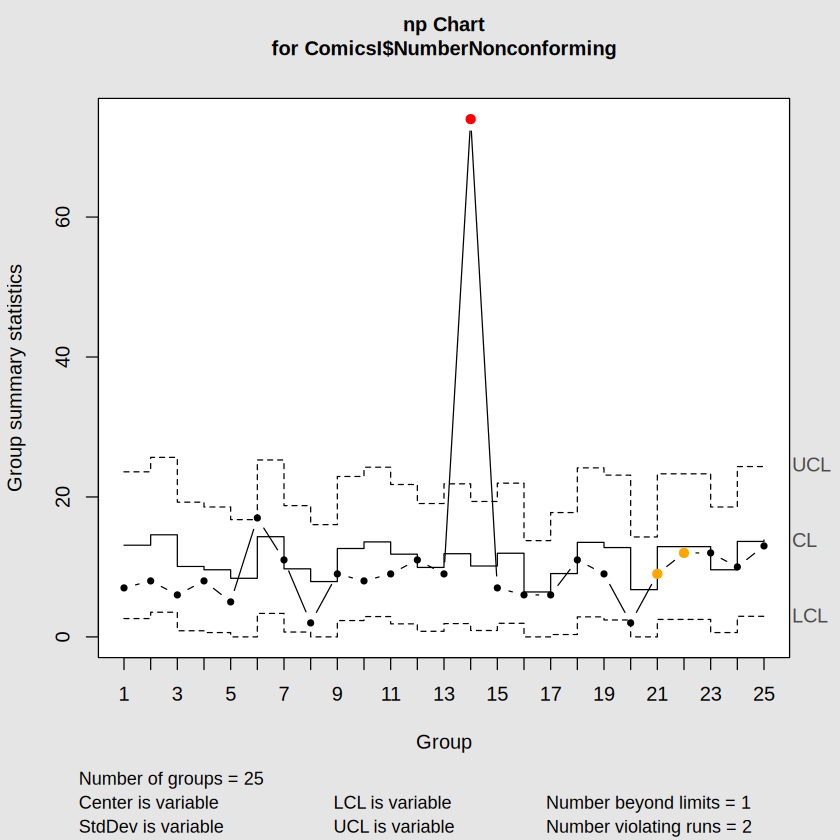

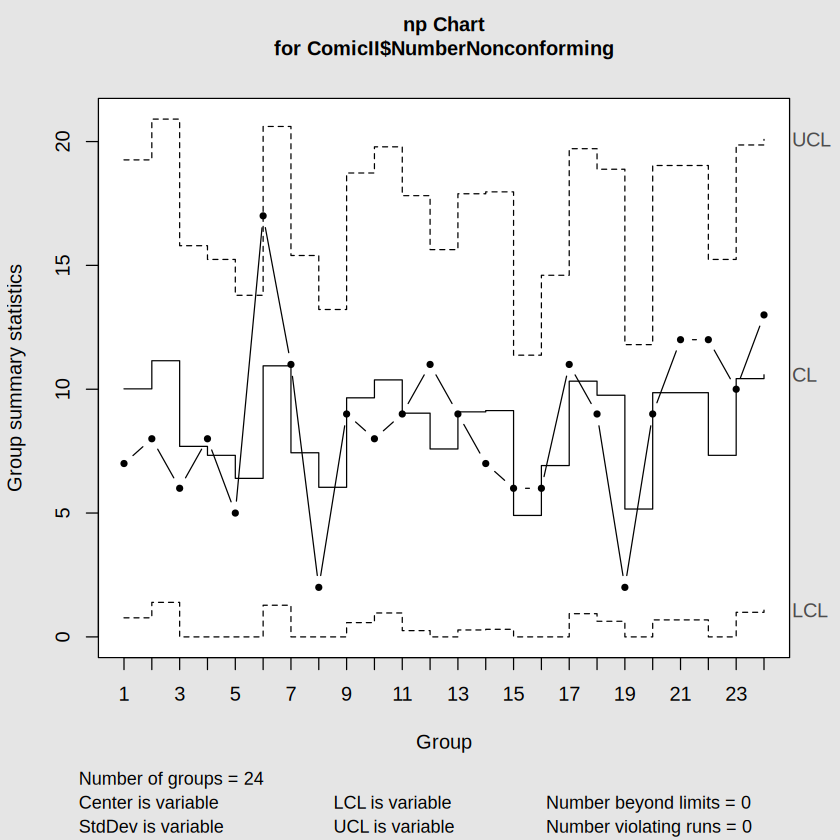

In [4]:
## Q5 Code ##

## Data Integrity Check ##

ComicsI |>
  glimpse()


  Comic_chart <- qcc(ComicsI$`NumberNonconforming`,
                    type="np",
                    sizes=ComicsI$`TotalComics`,
                    plot=TRUE)


ooc_points <- Comic_chart$violations$beyond.limits

ComicII <- ComicsI[-ooc_points,]

Comic_chart2 <- qcc(ComicII$`NumberNonconforming`,
                    type="np",
                    sizes=ComicII$`TotalComics`,
                    plot=TRUE)

### Q6: Using your finalized Phase I estimate of $\bar{p}$, report the center line and control limits you will carry forward into Phase II.

[1] 0.05162095

,LCL,UCL
,0.003964205,0.09927769
,0.006456330,0.09678557
,0.000000000,0.10600006
,0.000000000,0.10732426
,0.000000000,0.11123030
,0.006032239,0.09720966
,0.000000000,0.10693608
,0.000000000,0.11298758
,0.003080429,0.10016147
,0.004801403,0.09844049


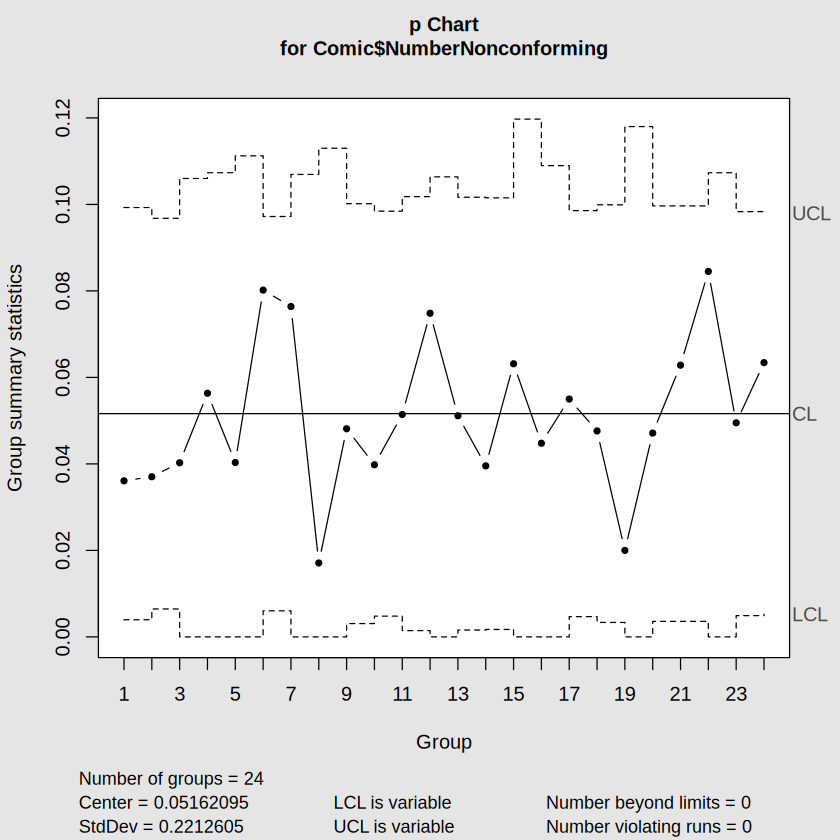

In [9]:
## Q6 Code ##

Comic_chart1 <- qcc(Comic$NumberNonconforming,
                    type="p",
                    sizes=Comic$TotalComics)
pbar <- Comic_chart1$center
limits <- Comic_chart1$limits

pbar
limits


comic_pchart_p2 <- qcc(Comic$NumberNonconforming,
                       type="p",
                       sizes=Comic$TotalComics,
                       center = pbar,
                       limits = limits,
                       plot = TRUE)








## Improve

### Q7: After seeing your Phase I results, Ravi calls the distributor, who agrees to add cardboard stiffeners to every shipping box going forward. Briefly explain why it would not be appropriate to use your *original* (uncleaned) Phase I control limits, rather than the finalized limits from Q6, to judge whether this packaging fix actually worked.

## Control

### Q8: Read the Phase II Shipment Condition data into R. Using your finalized Phase I center line and control limits from Q6, construct the Phase II $p$ chart. Do any weeks plot outside the control limits? Does this support the conclusion that the packaging fix worked?

Rows: 20
Columns: 3
$ Week                <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ TotalComics         <dbl> 134, 188, 91, 143, 161, 133, 92, 150, 189, 145, 13…
$ NumberNonconforming <dbl> 6, 1, 5, 1, 10, 4, 1, 3, 6, 3, 3, 5, 2, 5, 4, 2, 5…


Warning message in statistics > ucl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics < lcl:
“longer object length is not a multiple of shorter object length”


List of 11
 $ call      : language qcc(data = Comic$NumberNonconforming, type = "p", sizes = Comic$TotalComics)
 $ type      : chr "p"
 $ data.name : chr "Comic$NumberNonconforming"
 $ data      : num [1:24, 1] 7 8 6 8 5 17 11 2 9 8 ...
  ..- attr(*, "dimnames")=List of 2
 $ statistics: Named num [1:24] 0.0361 0.037 0.0403 0.0563 0.0403 ...
  ..- attr(*, "names")= chr [1:24] "1" "2" "3" "4" ...
 $ sizes     : num [1:24] 194 216 149 142 124 212 144 117 187 201 ...
 $ center    : num 0.0516
 $ std.dev   : num 0.221
 $ nsigmas   : num 3
 $ limits    : num [1:24, 1:2] 0.00396 0.00646 0 0 0 ...
  ..- attr(*, "dimnames")=List of 2
 $ violations:List of 2
 - attr(*, "class")= chr "qcc"

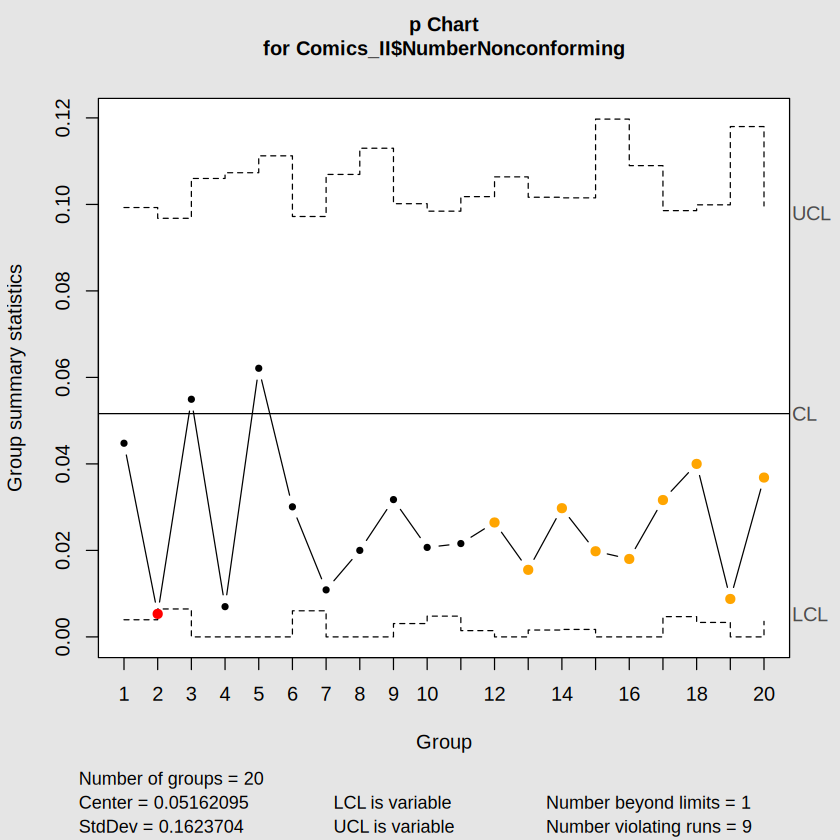

In [11]:
## Q8 Code ##
library(tidyverse)
library(readxl)
library(qcc)

## Read in the Data ##

Comics_II <- read_excel("RavisComics_ShipmentCondition_PhaseII.xlsx")

## Data Integrity Check ##

Comics_II|>
  glimpse()

#Limits and center from question 6
pbar <- Comic_chart1$center
limits <- Comic_chart1$limits

comic_p <- qcc(Comics_II$NumberNonconforming,
                       type="p",
                       sizes=Comics_II$TotalComics,
                       center = pbar,
                       limits = limits,
                       plot = TRUE)

 Comic_chart1


### Q9: Repeat Q8 using an $np$ chart instead. Is your conclusion consistent with Q8?

Warning message in statistics > ucl:
“longer object length is not a multiple of shorter object length”
Warning message in statistics < lcl:
“longer object length is not a multiple of shorter object length”


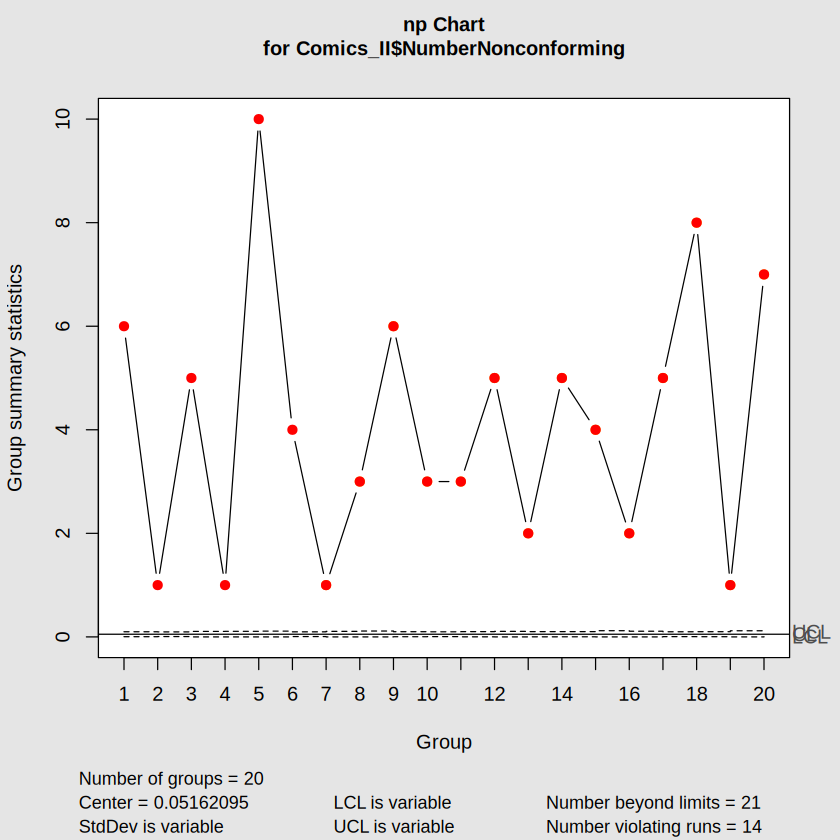

In [12]:
## Q9 Code ##

npbar <- Comic_chart1$center
nlimits <- Comic_chart1$limits

comic_np <- qcc(Comics_II$NumberNonconforming,
                       type="np",
                       sizes=Comics_II$TotalComics,
                       center = npbar,
                       limits = nlimits,
                       plot = TRUE)

### Q10: Read the New-Release Defect Counts data (Dataset B) into R. Construct a $c$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Rows: 25
Columns: 3
$ Week            <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,…
$ BoxesInspected  <dbl> 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, …
$ NumberOfDefects <dbl> 14, 8, 9, 8, 11, 10, 10, 52, 11, 10, 10, 12, 6, 11, 6,…


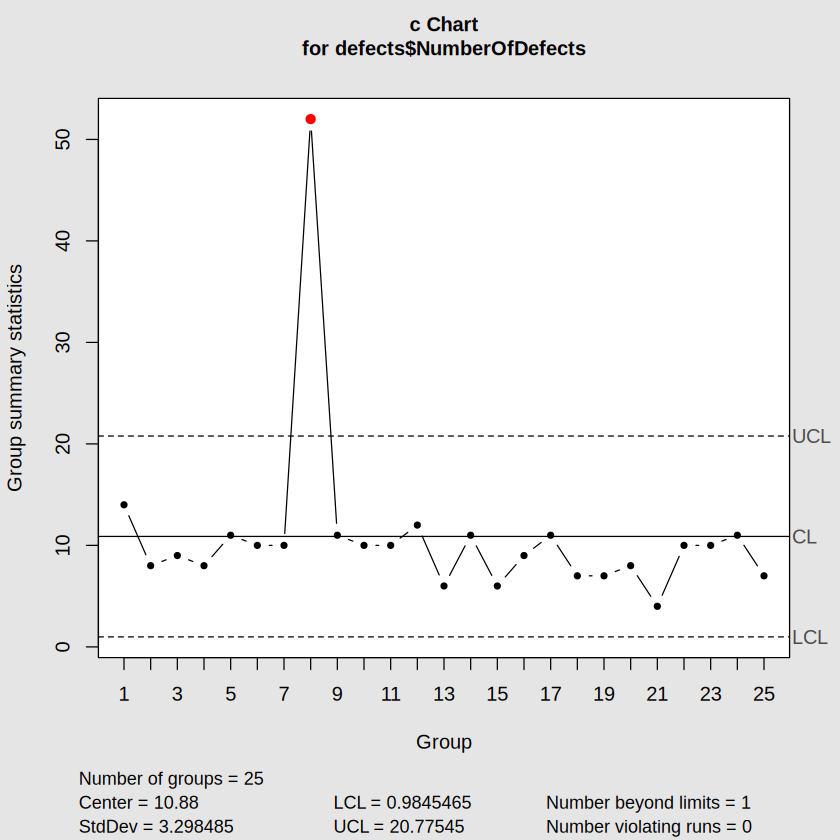

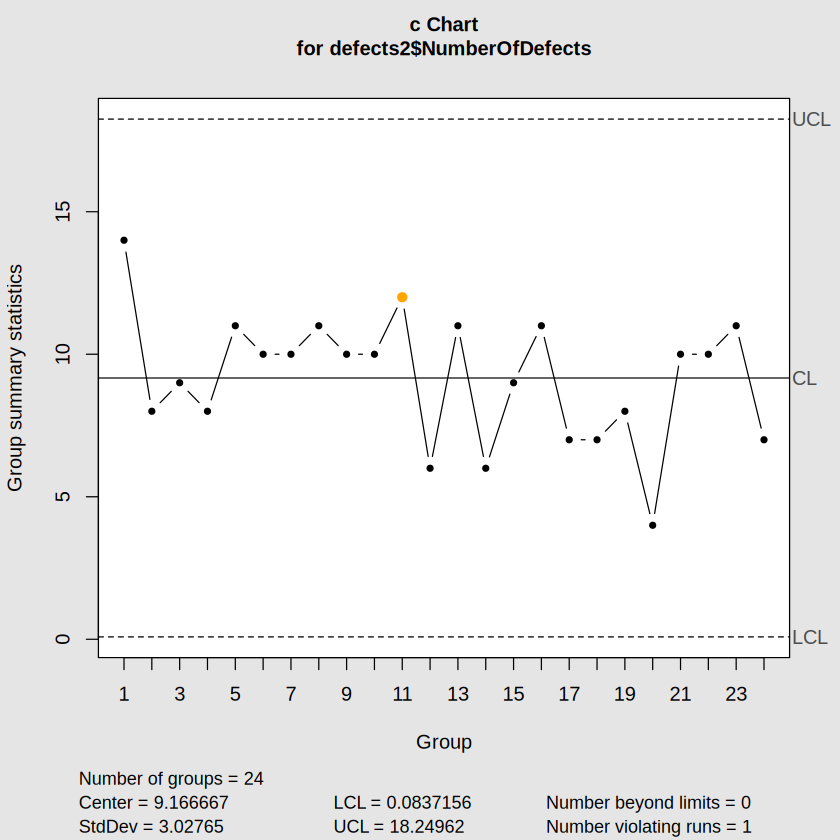

In [22]:
## Q10 Code ##

library(tidyverse)
library(readxl)
library(qcc)

## Read in the Data ##

defects <- read_excel("RavisComics_NewReleaseDefectCounts.xlsx")

## Data Integrity Check ##

defects|>
  glimpse()
## Plot Phase I C-Chart ##

defects_chart <- qcc(defects$`NumberOfDefects`,
                     sizes=defects$`BoxesInspected`,
                          type="c",plot=T)

ooc_points_defects <- defects_chart$violations$beyond.limits

defects2 <- defects[-ooc_points_defects,]

defects_chart2 <- qcc(defects2$`NumberOfDefects`,
                     sizes=defects2$`BoxesInspected`,
                          type="c",plot=T)


### Q11: Using your finalized $c$ chart, report $\bar{c}$ and the control limits. In 1-2 sentences, explain what this chart tells Ravi that the Q4-Q9 pass/fail analysis could not.

In [ ]:
## Q11 Code ##

### Q12: Read the Back-Issue Defect Counts data (Dataset C) into R. Construct a $u$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control week(s) by number and provide a contextual explanation as to why these OOC point(s) may have been observed, omit them, and replot the chart until statistical control is observed.

Rows: 25
Columns: 3
$ Week            <dbl> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,…
$ BoxesInspected  <dbl> 8, 10, 5, 3, 4, 5, 8, 2, 9, 8, 9, 10, 3, 4, 9, 2, 6, 8…
$ NumberOfDefects <dbl> 9, 11, 0, 2, 2, 9, 5, 1, 14, 5, 6, 11, 6, 7, 16, 3, 34…


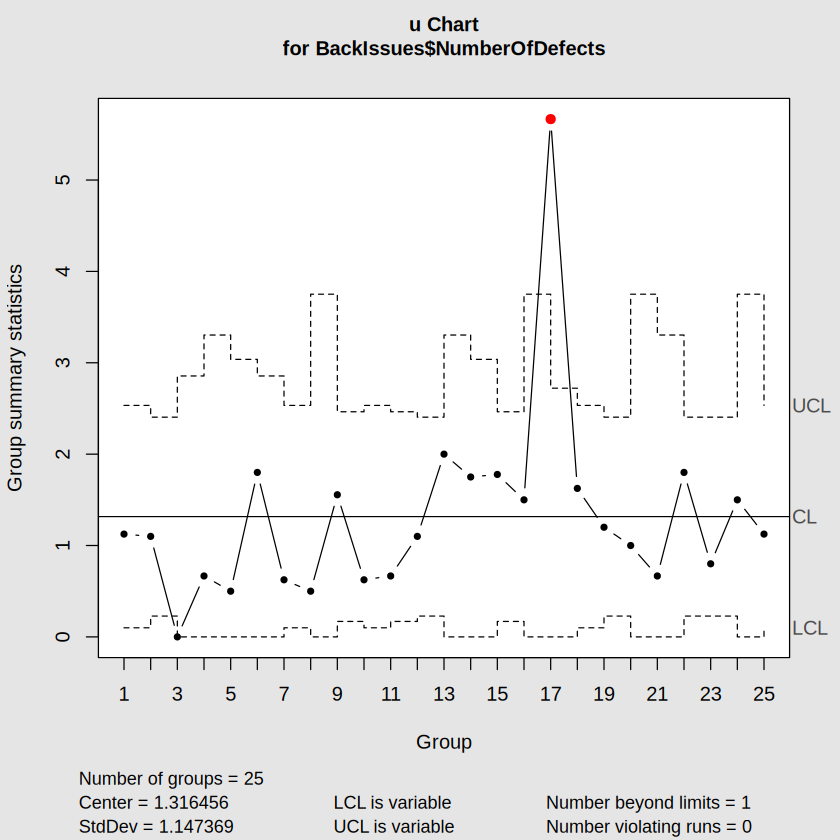

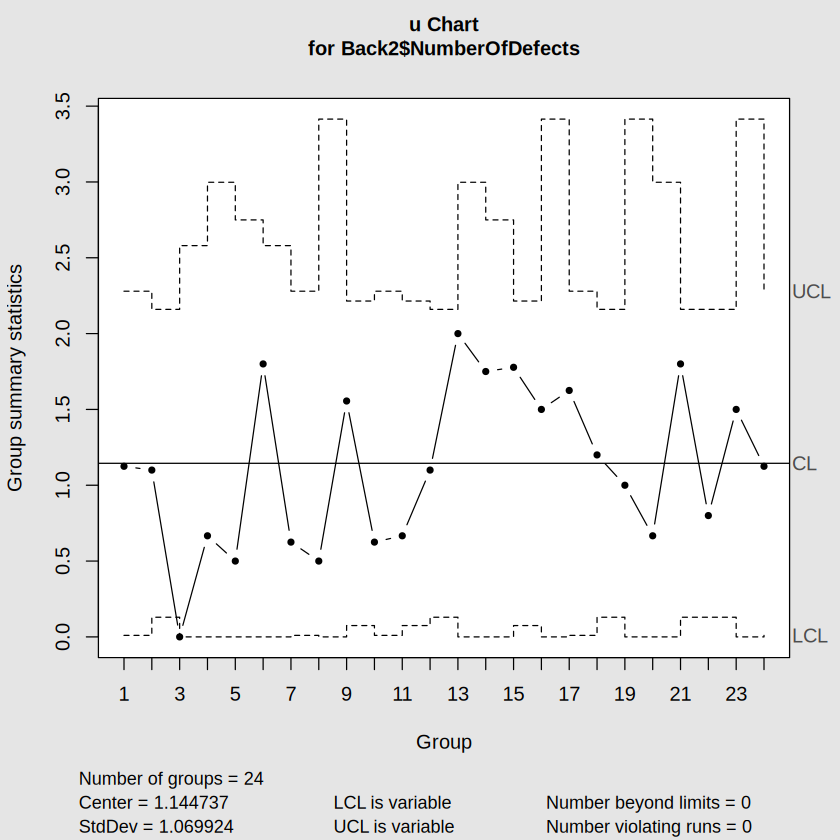

In [25]:
## Q12 Code ##
library(tidyverse)
library(readxl)
library(qcc)

## Read in the Data ##

BackIssues <- read_excel("RavisComics_BackIssueDefectCounts.xlsx")

## Data Integrity Check ##

BackIssues|>
  glimpse()
## Plot Phase I C-Chart ##

Back_chart <- qcc(BackIssues$`NumberOfDefects`,
                     sizes=BackIssues$`BoxesInspected`,
                          type="u",plot=T)

ooc_points_back <- Back_chart$violations$beyond.limits

Back2 <- BackIssues[-ooc_points_back,]

Back_chart2 <- qcc(Back2$`NumberOfDefects`,
                     sizes=Back2$`BoxesInspected`,
                          type="u",plot=T)




### Q13: Suppose you tried to build a $c$ chart on the Back-Issue Defect Counts data instead of a $u$ chart. Why would this not be an appropriate choice, given how the data were collected?

### Q14: Provide an overview of your results that Ravi can use the next time he calls the distributor's account representative. Citing specific evidence from your $p$/$np$ analysis **and** your $c$/$u$ analysis, which parts of the damage problem look like they're the distributor's responsibility, and which parts (if any) look more like an internal, in-shop handling issue?